# Evaluar TASC cuando la evidencia es ambigua o no está disponible

**Pregunta:** ¿Aportan los supuestos de tiempo, motor y topología de TASC una localización confiable al contar
la ambigüedad, los rechazos y las comparaciones desfavorables?

Nivel 4 · Requisitos: lecciones 01–03; interpretar conteos puntuales antes de porcentajes. · Lectura: 50 minutos.

## Objetivos

Un grafo de factores puede explicar qué observaciones contribuyeron a una inconsistencia sin demostrar
qué fuente la causó. Ejecutaremos Topology-Aware State Coherence, inspeccionaremos un factor local de
evidencia, construiremos una discrepancia ambigua de flotación y retiraremos observaciones con y sin
cobertura de motor. Luego ejecutaremos la comparación canónica con casos reservados y recalcularemos
incertidumbre pareada desde el benchmark completo registrado. Los resultados desfavorables y estados no
observables deben sobrevivir al análisis; no son obstáculos que debamos ocultar para defender una afirmación.

## Preparación

Trabaja en una copia de OreBridge con el entorno de notebooks activo. Los métodos computacionales están en
`data-pipeline/pipeline`; se necesita el repositorio y no se presupone una distribución OreBridge en PyPI.
Instala estas dependencias numéricas exactas una vez, fuera de este notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Inicia el kernel con `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` y `MKL_NUM_THREADS=1`.
La preparación encuentra el repositorio desde el directorio de trabajo sin imprimir una ruta de la máquina.

In [1]:
# Usar el entorno de CPU con versiones fijas e importar los métodos científicos implementados.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.scenarios import generate, align, channel_specs, conservation_matrix, engine_prior
from pipeline.model.reconciliation import tasc
from pipeline.model.learning import fit_normal
from pipeline.stages.plant_evaluate import calibrate, evaluate_one
from pipeline.stages.analysis import analyze
benchmark = json.loads((root / "data/derived/benchmark.json").read_text(encoding="utf-8"))
committed_analysis = json.loads((root / "data/derived/benchmark-analysis.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Datos

Responsable: OreBridge, [repositorio público MIT](https://github.com/fsantibanezleal/CAOS_OreBridge);
categoría sintética de autoría del proyecto. `data/derived/benchmark.json` contiene 768 escenarios × 8 métodos
y los conteos puntuales efectivos. `data/derived/benchmark-analysis.json` registra el protocolo complementario.
Las semillas de prueba son 1000–1015 y las severidades 0.5, 1, 2 y 4, separadas del ajuste y de dos grupos de
calibración. Regeneraremos los casos locales con el mismo generador implementado. No se han suministrado
geometrías ni mediciones reales de una planta; los ejemplos independientes de motores siguen siendo casos de referencia.

## Método

TASC combina observaciones admitidas $y$ y pseudoobservaciones compatibles de motor $m$. Su objetivo es
$\sum_{j\in V}\rho_\delta((x_j-y_j)/\sigma_j)+
\sum_{j\in E}\rho_\delta((x_j-m_j)/\tau_j)$, sujeto a $Ax=b$.
La pérdida de Huber limita la influencia de residuos grandes ([Huber](https://doi.org/10.1214/aoms/1177703732)); la conservación aporta
factores de igualdad ([conciliación mineralúrgica](https://doi.org/10.1016/j.mineng.2018.04.023)). Ninguno de los dos ingredientes identifica por
sí solo una causa. OreBridge propone esta combinación concreta con alineación, validez y procedencia local.
Los antecedentes de relaciones aprendidas entre sensores, como [GDN](https://arxiv.org/abs/2106.06947), siguen siendo pertinentes.

El prior de motor usa aquí relaciones fijas de sólidos ancladas a un punto operativo de referencia y se
calcula únicamente desde alimentación observada. No recibe verdad limpia. Los canales de agua no tienen
cobertura de motor. Usamos la incertidumbre nominal del cuatro por ciento del benchmark; no es un intervalo
de confianza ajustado. Comenzamos con sesgo de alimentación de severidad cuatro, alineamos observaciones
y pedimos al estimador por fila su estado e innovaciones de factores sobre las observaciones originales.
La innovación es $A_i y-b_i$, normalizada por $\sqrt{\sum_j(A_{ij}\sigma_j)^2}$ cuando todas las entradas son válidas.

In [2]:
# Fusionar solo magnitudes con cobertura y conservar las observaciones originales del factor.
specs = channel_specs()
sigma = np.array([s["sigma"] for s in specs])
nominal = np.array([s["nominal"] for s in specs])
matrix = conservation_matrix()
case = generate("bias", seed=1000, severity=4)
aligned_values = align(case.observed)
aligned_valid = align(case.valid)
prior, coverage = engine_prior(aligned_values)
engine_sigma = np.maximum(0.04 * nominal, 0.4)
fused = tasc(aligned_values[90], sigma, matrix, np.zeros(11), valid=aligned_valid[90],
             engine=prior[90], engine_sigma=engine_sigma, engine_valid=coverage[90])
factor = fused["evidence"][4]
print(f"Innovación del factor de flotación: {factor['innovation']:.6f} t/h; normalizada: {factor['normalized']:.6f} σ")
print(f"Mayor residuo del estado estimado: {np.max(np.abs(fused['balance_residual'])):.12f}")
print("Canales contribuyentes:", [specs[j]["id"] for j in factor["channels"]])

Innovación del factor de flotación: 104.802367 t/h; normalizada: 10.424566 σ
Mayor residuo del estado estimado: 0.000000000000
Canales contribuyentes: ['FL1.feed', 'FL1.concentrate', 'FL1.tailings']


Una innovación normalizada grande señala un conjunto pequeño de lecturas incompatibles. Para ver su límite
volvemos a tres canales de flotación. Diez t/h adicionales en alimentación y diez t/h faltantes en relaves
producen la misma discrepancia escalar. Ambas hipótesis explican un residuo único aunque involucren
instrumentos distintos. Ejecutamos TASC con ese vector pequeño e imprimimos el rango. Un óptimo numérico
único no elimina la ambigüedad física de dos dimensiones.

In [3]:
# Demostrar discrepancias de falla indistinguibles con unidades y restricciones reales de los canales.
columns = [5, 6, 7]
flotation_matrix = matrix[4:5, columns]
candidate_faults = np.array([[10.0, 0.0, 0.0], [0.0, 0.0, -10.0]])
syndromes = candidate_faults @ flotation_matrix.T
ambiguous = nominal[columns] + candidate_faults[0]
small_result = tasc(ambiguous, sigma[columns], flotation_matrix, [0.0])
print("Discrepancias de dos fallas candidatas:", syndromes.ravel(), "t/h")
print(f"Rango de la restricción de flotación: {np.linalg.matrix_rank(flotation_matrix)}; direcciones libres: 2")
print("Ajustes TASC sin prior de motor:", np.round(small_result["state"] - ambiguous, 6), "t/h")

Discrepancias de dos fallas candidatas: [10. 10.] t/h
Rango de la restricción de flotación: 1; direcciones libres: 2
Ajustes TASC sin prior de motor: [-5.129072e+00  3.423000e-03  4.867505e+00] t/h


Retiramos una observación de sólidos que sí cuenta con una fila compatible de motor. El estimador por fila
puede devolver un estado asistido por modelo, pero la puntuación de esa observación debe seguir sin
información disponible y el factor que la necesita debe declararse no observado. La máscara de validez
sintética emula un rechazo del contrato de ingreso; no aprende a detectar relojes obsoletos, unidades erróneas
ni etiquetas intercambiadas.

In [4]:
# Mantener inválida la observación faltante aunque el motor permita estimar un estado.
missing_dry = aligned_values[90].copy()
dry_valid = aligned_valid[90].copy()
missing_dry[5] = np.nan
dry_valid[5] = False
dry_result = tasc(missing_dry, sigma, matrix, np.zeros(11), valid=dry_valid, engine=prior[90],
                  engine_sigma=engine_sigma, engine_valid=coverage[90])
print("Estado de sólidos secos:", "estimado" if dry_result["state_status"] == "estimated" else "rechazado")
print("Puntuación de observación faltante:", dry_result["score"][5])
print("Factor de flotación observado:", "sí" if dry_result["evidence"][4]["observed"] else "no")
innovation = dry_result["evidence"][4]["innovation"]
print("Innovación del factor sin información:", "nulo" if innovation is None else innovation)

Estado de sólidos secos: estimado
Puntuación de observación faltante: nan
Factor de flotación observado: no
Innovación del factor sin información: nulo


Repetimos la eliminación en la entrada del estanque, sin cobertura del motor de sólidos. La regla
implementada exige observación o fila de motor para cada coordenada; en otro caso devuelve no observable.
Algunas redes permitirían identificar una coordenada faltante solo mediante conservación, pero esta rutina
no realiza ese análisis general de observabilidad. Mostramos el rechazo efectivo en lugar de atribuirle
una capacidad de recuperación inexistente.

In [5]:
# Ejercer el rechazo conservador cuando ni medición ni motor compatible cubren una coordenada.
missing_water = aligned_values[90].copy()
water_valid = aligned_valid[90].copy()
missing_water[14] = np.nan
water_valid[14] = False
water_result = tasc(missing_water, sigma, matrix, np.zeros(11), valid=water_valid, engine=prior[90],
                    engine_sigma=engine_sigma, engine_valid=coverage[90])
print("Estado de agua:", "no observable" if water_result["state"] is None else "estimado")
print("Índices de canales inválidos:", water_result["invalid"])
coverage_text = ["sí" if good else "no" for good in coverage[90, 12:]]
print("Cobertura de motor en canales de agua:", coverage_text)

Estado de agua: no observable
Índices de canales inválidos: [14]
Cobertura de motor en canales de agua: ['no', 'no', 'no', 'no']


Inspeccionamos las lecturas originales y las estimaciones de la fila sesgada seleccionada. La figura conserva
la observación faltante como una ausencia; el estado asistido por motor se muestra con otro símbolo. Todos
los canales graficados son sólidos secos, por lo que la unidad vertical común tiene sentido. Inducimos
la invalidez después de generar el escenario para probar la frontera del método; no proviene de un detector
entrenado con estas lecturas.

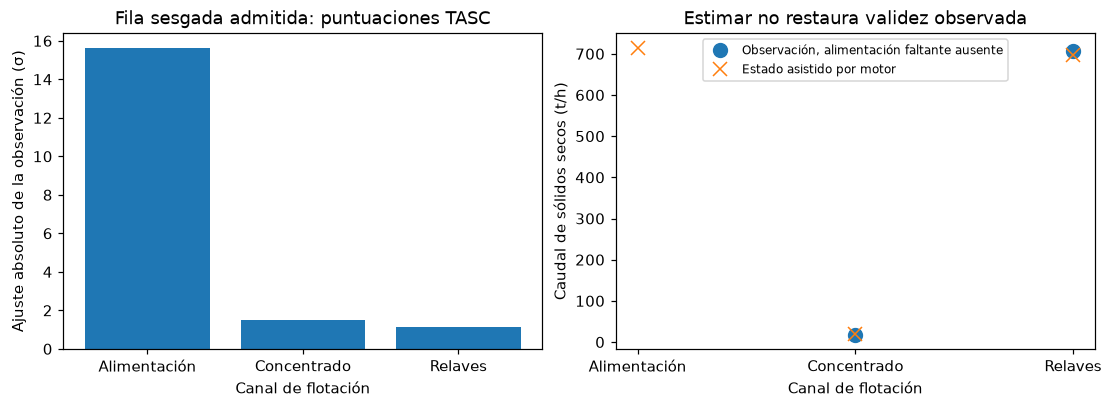

In [6]:
# Separar visiblemente observaciones originales y estados inferidos ante datos faltantes.
positions = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].bar(positions, fused["score"][columns])
axes[0].set(title="Fila sesgada admitida: puntuaciones TASC", ylabel="Ajuste absoluto de la observación (σ)")
axes[1].plot(positions, missing_dry[columns], "o", markersize=9, label="Observación, alimentación faltante ausente")
axes[1].plot(positions, dry_result["state"][columns], "x", markersize=9, label="Estado asistido por motor")
axes[1].set(title="Estimar no restaura validez observada", ylabel="Caudal de sólidos secos (t/h)")
axes[1].legend(fontsize=8)
for axis in axes:
    axis.set_xticks(positions, ["Alimentación", "Concentrado", "Relaves"])
    axis.set_xlabel("Canal de flotación")
plt.show()

El primer panel localiza la corrección grande en una parte pequeña del balance, pero las discrepancias
indistinguibles anteriores impiden convertir esa localización en prueba de causa. En el segundo no aparece
un marcador observado de alimentación: el estado asistido no fabricó una lectura instrumental. Su innovación
de factor siguió nula. La misma implementación rechazó la coordenada de agua sin cobertura. Una interfaz
debe conservar tanto la ausencia como el estado explícito, sin presentar ninguno como sano.

## Comparación

El benchmark canónico usa una política por lote deliberadamente más estricta que el ejemplo por fila.
Primero excluye lecturas rechazadas y arrastra el último valor finito solo para entrada numérica, nunca para mostrar observaciones.
Una lectura finita rechazada no puede incorporarse al historial del modelo.
Si alguna observación requerida de una fila restringida es inválida, sus dieciséis puntuaciones numéricas
quedan sin información disponible. El rechazo de calidad se evalúa aparte. El pronóstico recibe entradas
finitas mediante ese arrastre declarado, mientras la observación inválida se excluye de la comparación
numérica. Estas políticas cambian los denominadores y deben acompañar la precisión y las falsas alertas agregadas.

La perturbación de recuperación satisface $A\Delta\approx0$ en el tiempo simultáneo sin alinear. Los
desplazamientos distintos de cada canal llevan su inicio y término a tiempos alineados diferentes; una
fila alineada puede abarcar un límite del evento. La alineación puede entonces introducir residuos de
factores distintos de cero aunque la perturbación simultánea estuviera balanceada. El caso canónico prueba
conjuntamente la compatibilidad del prior fijo y estos efectos transitorios de alineación. Su sensibilidad
no permite aislar solo la compatibilidad del prior. El cálculo del espacio nulo simultáneo de la lección 03
conserva su interpretación original.

Ajustamos nuevamente el predictor normal y calibramos los métodos canónicos con semillas separadas. Se
ejecuta el estimador por histogramas descrito en su [documentación oficial](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html),
sin cargar el checkpoint registrado. No lo reajustaremos ni cambiaremos umbrales tras examinar las pruebas.

In [7]:
# Recrear el ajuste normal y el protocolo canónico de umbrales fijos antes de evaluar pruebas reservadas.
bundle = fit_normal()
thresholds = calibrate(bundle)
print(f"Filas de entrenamiento: {bundle['normal_training_rows']}; "
      f"filas de calibración predictiva: {bundle['calibration_rows']}")
print("Grupos de semillas separados:", bundle["train_seeds"], bundle["calibration_seeds"], list(range(300, 308)))

Filas de entrenamiento: 1568; filas de calibración predictiva: 784
Grupos de semillas separados: [100, 101, 102, 103, 104, 105, 106, 107] [200, 201, 202, 203] [300, 301, 302, 303, 304, 305, 306, 307]


Ejecutamos los ocho métodos para un cambio de recuperación, el control negativo de retardo no modelado y
un caso de agua faltante. La familia de retardo no inyecta fallas instrumentales; toda alarma de proceso
allí es falsa. La familia faltante prueba rechazo declarado de entrada, no capacidad aprendida para
descubrir ausencia. Conservamos la sensibilidad indefinida y los puntos sin puntuación. Los nombres del
objeto de resultados son identificadores estables del pipeline; las descripciones impresas explican su significado.

In [8]:
# Ejecutar las ablaciones efectivas y conservar el soporte rechazado junto a las métricas de detección.
method_labels = {"threshold": "Umbral fijo", "wls": "WLS", "robust-aligned": "Huber alineado",
                 "forecast": "HGB", "tasc": "TASC", "tasc-no-timing": "TASC sin tiempos",
                 "tasc-no-engine": "TASC sin motor", "tasc-no-topology": "TASC sin topología"}
family_labels = {"engine": "Cambio de recuperación", "delay": "Control de retardo", "missing": "Agua faltante"}
selected_rows = {}
for family in ["engine", "delay", "missing"]:
    rows, outputs, _ = evaluate_one(generate(family, seed=1000, severity=2), bundle, thresholds)
    selected_rows[family] = {row["method"]: row for row in rows}
for family, methods in selected_rows.items():
    for method in ["robust-aligned", "forecast", "tasc", "tasc-no-topology"]:
        row = methods[method]
        recall = row["numeric"]["recall"]
        recall_text = "nulo (indefinido)" if recall is None else f"{recall:.6f}"
        print(f"{family_labels[family]}/{method_labels[method]}: sensibilidad={recall_text}; "
              f"falsas alarmas={row['numeric']['fp']}; "
              f"entradas sin puntuación={row['unscorable_points']}")

Cambio de recuperación/Huber alineado: sensibilidad=0.023333; falsas alarmas=16; entradas sin puntuación=0
Cambio de recuperación/HGB: sensibilidad=0.970000; falsas alarmas=19; entradas sin puntuación=0
Cambio de recuperación/TASC: sensibilidad=0.036667; falsas alarmas=15; entradas sin puntuación=0
Cambio de recuperación/TASC sin topología: sensibilidad=0.500000; falsas alarmas=7; entradas sin puntuación=0
Control de retardo/Huber alineado: sensibilidad=nulo (indefinido); falsas alarmas=56; entradas sin puntuación=0
Control de retardo/HGB: sensibilidad=nulo (indefinido); falsas alarmas=31; entradas sin puntuación=0
Control de retardo/TASC: sensibilidad=nulo (indefinido); falsas alarmas=55; entradas sin puntuación=0
Control de retardo/TASC sin topología: sensibilidad=nulo (indefinido); falsas alarmas=67; entradas sin puntuación=0
Agua faltante/Huber alineado: sensibilidad=nulo (indefinido); falsas alarmas=9; entradas sin puntuación=800
Agua faltante/HGB: sensibilidad=nulo (indefinido); 

## Evidencia

El caso local de recuperación muestra la baja sensibilidad de TASC en la prueba conjunta de compatibilidad
del prior y alineación; el control de retardo muestra el costo de un transporte mal especificado; el caso
faltante cuenta una abstención explícita. Ninguno
se presenta como promedio representativo. Para ampliar cobertura usamos todos los conteos del benchmark
registrado y volvemos a ejecutar su análisis implementado. Esto no repite las 768 simulaciones dentro del
notebook: la matriz fija entra a un nuevo análisis pareado y las celdas anteriores sí ejecutaron estimadores.

El análisis remuestrea dieciséis bloques de semillas reservadas 5000 veces con semilla 414. Mantiene juntas
familias, severidades y dependencias canal-tiempo de cada semilla, sin tratar millones de puntos correlacionados
como ensayos independientes. Los intervalos describen este experimento sintético, no incertidumbre del
desempeño de campo. La rutina restaura razones nulas por familia cuando el denominador es cero, aunque
internamente usa ceros para la aritmética del remuestreo. Inspeccionamos explícitamente esa frontera.

In [9]:
# Recalcular incertidumbre pareada por semilla desde todos los conteos y conservar razones nulas.
analysis = analyze(benchmark, replicates=5000)
print(f"Celdas método/escenario: {len(benchmark['rows'])}; "
      f"semillas reservadas: {len(benchmark['protocol']['test_seeds'])}")
print(f"Réplicas del remuestreo pareado: {analysis['protocol']['replicates']}")
delay_family = next(r for r in analysis["by_family"] if r["family"] == "delay" and r["method"] == "tasc")
delay_recall = delay_family["ratios"][1]
print("Sensibilidad TASC en control de retardo, indefinida:", "nulo" if delay_recall is None else delay_recall)
print("Falsas alarmas TASC del control de retardo en la matriz:", delay_family["counts"][1])

Celdas método/escenario: 6144; semillas reservadas: 16
Réplicas del remuestreo pareado: 5000
Sensibilidad TASC en control de retardo, indefinida: nulo
Falsas alarmas TASC del control de retardo en la matriz: 3532


La matriz completa tiene soportes numéricos distintos. Recalculamos conteos agregados y conservamos los
rechazos junto a sensibilidad y falsos positivos. El análisis de fuentes válidas elimina las cinco familias
de rechazo para comparar con soporte común. Su orden de sensibilidad sigue importando sin datos inválidos.
Una tasa agregada menor de falsos positivos no es una victoria sin condiciones si el método rechazó más entradas.

In [10]:
# Recalcular la evidencia agregada y mostrar los distintos denominadores de abstención.
method_order = [r["method"] for r in benchmark["aggregate"]]
aggregate = {}
for method in method_order:
    subset = [r for r in benchmark["rows"] if r["method"] == method]
    counts = {key: sum(r["numeric"][key] for r in subset) for key in ["tp", "fp", "fn", "tn"]}
    counts["recall"] = counts["tp"] / (counts["tp"] + counts["fn"])
    counts["fpr"] = counts["fp"] / (counts["fp"] + counts["tn"])
    counts["unscorable"] = sum(r["unscorable_points"] for r in subset)
    aggregate[method] = counts
    print(f"{method_labels[method]}: sensibilidad={100 * counts['recall']:.6f}%; "
          f"tasa de falsos positivos={100 * counts['fpr']:.6f}%; "
          f"sin puntuación={counts['unscorable']}")
matched = {r["method"]: r for r in analysis["matched_source_valid"]}
common_methods = ["tasc", "forecast", "tasc-no-topology"]
common_recalls = {method_labels[m]: round(matched[m]["recall"], 6) for m in common_methods}
print("Sensibilidad en el subconjunto común de fuentes válidas:", common_recalls)

Umbral fijo: sensibilidad=30.650000%; tasa de falsos positivos=0.000000%; sin puntuación=16000
WLS: sensibilidad=14.809375%; tasa de falsos positivos=0.961125%; sin puntuación=256000
Huber alineado: sensibilidad=33.621875%; tasa de falsos positivos=0.896452%; sin puntuación=256000
HGB: sensibilidad=83.993750%; tasa de falsos positivos=1.591022%; sin puntuación=16000
TASC: sensibilidad=34.190625%; tasa de falsos positivos=0.888152%; sin puntuación=256000
TASC sin tiempos: sensibilidad=23.475000%; tasa de falsos positivos=0.664786%; sin puntuación=256000
TASC sin motor: sensibilidad=33.621875%; tasa de falsos positivos=0.896452%; sin puntuación=256000
TASC sin topología: sensibilidad=51.909375%; tasa de falsos positivos=0.578999%; sin puntuación=256000
Sensibilidad en el subconjunto común de fuentes válidas: {'TASC': 0.341906, 'HGB': 0.839938, 'TASC sin topología': 0.519094}


Situamos todos los métodos y ablaciones en los mismos dos ejes. Conservamos el umbral simple: sus cero
falsas alertas acompañan sensibilidad baja y no demuestran localización resuelta. Retirar el motor debe
reproducir la proyección robusta alineada; retirar topología revela si esos factores ayudan en este generador.
Las ablaciones prueban necesidad bajo los supuestos del experimento, sin demostrar que la conservación
física sea inútil en general.

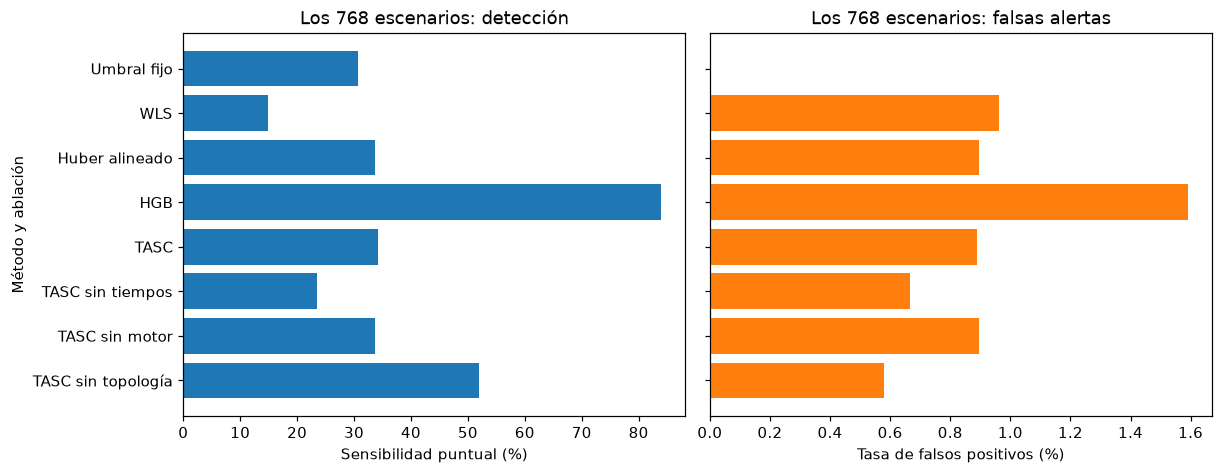

In [11]:
# Mostrar el resultado negativo de topología junto a todas las alternativas informadas.
labels = ["Umbral fijo", "WLS", "Huber alineado", "HGB", "TASC",
          "TASC sin tiempos", "TASC sin motor", "TASC sin topología"]
positions = np.arange(len(method_order))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", sharey=True)
axes[0].barh(positions, [100 * aggregate[m]["recall"] for m in method_order])
axes[1].barh(positions, [100 * aggregate[m]["fpr"] for m in method_order], color="tab:orange")
axes[0].set_yticks(positions, labels)
axes[0].invert_yaxis()
axes[0].set(title="Los 768 escenarios: detección", xlabel="Sensibilidad puntual (%)", ylabel="Método y ablación")
axes[1].set(title="Los 768 escenarios: falsas alertas", xlabel="Tasa de falsos positivos (%)")
plt.show()

TASC mejora apenas la sensibilidad de Huber alineado, queda muy por debajo del predictor y pierde frente
a su propia ablación sin topología tanto en sensibilidad como en falsos positivos. El resultado sin motor
coincide con Huber alineado, como exige la construcción. Retirar tiempos reduce sensibilidad y falsas
alertas: es un intercambio, no un veredicto unidimensional. El subconjunto común de fuentes válidas mantiene
ese orden desfavorable; el resultado negativo de topología no se explica únicamente por datos faltantes.

Graficamos las diferencias pareadas de sensibilidad con sus intervalos por bloque. La comparación con el
predictor tiene más incertidumbre porque el desempeño varía entre cargas reservadas. El intervalo negativo
estrecho frente a retirar topología sigue describiendo solo este proceso de autoría propia y su prior fijo.
Más semillas no convierten un experimento mal especificado en validación de campo. La decisión siguiente
sería revisar supuestos y registrar una nueva evaluación reservada antes de medirla.

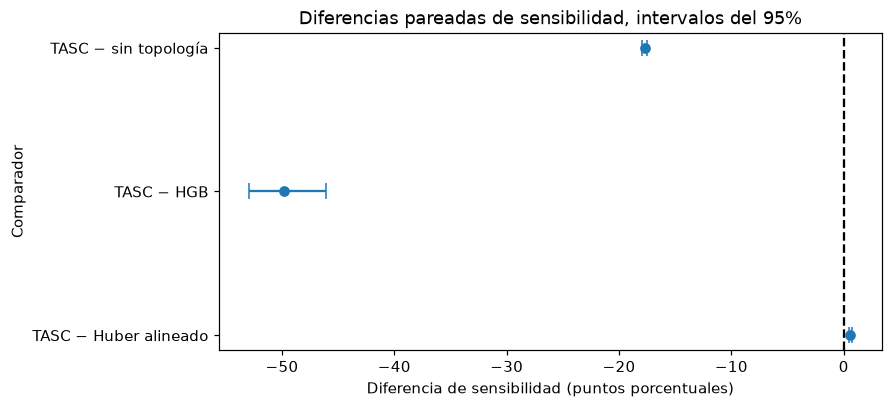

Huber alineado: 0.0056875; intervalo=[0.004375  0.0070938]
HGB: -0.4980312; intervalo=[-0.5293133 -0.4610281]
TASC sin topología: -0.1771875; intervalo=[-0.1792188 -0.1752812]


In [12]:
# Usar bloques pareados de semillas en vez de remuestrear puntos canal-tiempo independientes.
differences = [r for r in analysis["paired_differences"] if r["metric"] == "recall"]
point = np.array([r["difference"] for r in differences]) * 100
limits = np.array([r["ci95"] for r in differences]) * 100
errors = np.vstack([point - limits[:, 0], limits[:, 1] - point])
fig, axis = plt.subplots(figsize=(8, 3.6), layout="constrained")
axis.errorbar(point, np.arange(3), xerr=errors, fmt="o", capsize=5)
axis.axvline(0, color="black", linestyle="--")
axis.set_yticks(np.arange(3), ["TASC − Huber alineado", "TASC − HGB", "TASC − sin topología"])
axis.set(title="Diferencias pareadas de sensibilidad, intervalos del 95%",
         xlabel="Diferencia de sensibilidad (puntos porcentuales)", ylabel="Comparador")
plt.show()
for row in differences:
    print(f"{method_labels[row['reference']]}: {row['difference']:.7f}; "
          f"intervalo={np.round(row['ci95'], 7)}")

Los intervalos de sensibilidad mostrados no cruzan cero: la ganancia frente a Huber alineado es pequeña y
las pérdidas frente al predictor y la variante sin topología son grandes en esta matriz. Eso contradice
una superioridad general de la fusión propuesta. No decide qué componente retirar de una planta real,
donde instrumentación, inventario, topología e incertidumbre de motor compatible necesitan mediciones
independientes. Conservar esta conclusión desfavorable forma parte de la utilidad del experimento como
objeto de investigación reproducible.

## Resultados

**Respuesta:** El factor de flotación admitido tiene innovación de 104.802367 t/h, equivalente a 10.424566 σ,
pero dos hipótesis distintas de diez t/h comparten la misma discrepancia de balance. El sólido faltante con
cobertura permite un estado estimado separado y conserva puntuación observada NaN; el agua sin cobertura
devuelve un estado no observable. En 6144 celdas método/escenario, TASC tiene sensibilidad de 34.190625%,
frente a 33.621875% de Huber alineado, 83.993750% de HGB y 51.909375% al retirar topología. La diferencia
pareada frente a esa ablación es -0.1771875, con intervalo del 95% [-0.1792188, -0.1752812]. No sustenta una
localización general confiable ni superioridad.

TASC registra 256000 entradas numéricas sin puntuación en la matriz completa. Su control negativo de retardo
produce 3532 falsas alarmas y sensibilidad indefinida porque no hay falla instrumental. La ejecución local
de tres casos también conserva 800 entradas sin puntuación del caso faltante. Esos límites deben acompañar
la explicación atractiva del factor. Rechazo de calidad, estimación numérica, alarma de proceso y diagnóstico
causal son afirmaciones distintas.

## Resumen

TASC aporta una fusión robusta concreta y procedencia local, pero sus restricciones no eliminan ambigüedad y
la evidencia actual es negativa en comparaciones importantes. Ejercimos su frontera real de admisión,
ejecutamos ablaciones y recalculamos incertidumbre pareada sin descartar nulos ni rechazos. Un estudio futuro
requiere tiempos, inventarios y compatibilidad medidos, además de desempeño reservado que sobreviva al mismo
tratamiento transparente de los fallos.

## Referencias

- Huber (1964), pérdida robusta: https://doi.org/10.1214/aoms/1177703732
- Sadeghi, Hodouin y Bazin (2018), conciliación mineralúrgica: https://doi.org/10.1016/j.mineng.2018.04.023
- scikit-learn, estimador mantenido de potenciación por histogramas: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- Deng y Hooi (2021), antecedente de relaciones entre sensores, sin comparación GDN ejecutada: https://arxiv.org/abs/2106.06947
- TASC ejecutado: `data-pipeline/pipeline/model/reconciliation.py`; reglas exactas de soporte del benchmark:
  `data-pipeline/pipeline/stages/plant_evaluate.py`; remuestreo pareado: `data-pipeline/pipeline/stages/analysis.py`.
- Entradas fijas: `data/derived/benchmark.json`, `data/derived/benchmark-analysis.json`; supuestos:
  `docs/problem-types/02_state-coherence-experiment.md` y `docs/design/SDD.md`.